# exp02: Kontribusi Sensor

Menguji kelompok fitur F0–F7 dan pasangan dengan/tanpa rasio baseline. Logistic dan XGBoost fixed dipertahankan agar perubahan hasil dapat ditelusuri ke representasi sensor.


## Lokasi proyek

Notebook membaca data dan menyimpan hasil melalui Google Drive. Path utama adalah `/content/drive/MyDrive/Penelitian-Adaptive-IDE`. Tidak ada upload CSV melalui notebook.


In [1]:
from pathlib import Path
import os
import sys
from google.colab import drive

drive.mount('/content/drive')
IN_COLAB = True
PROJECT_ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
BATCH_DIR = PROJECT_ROOT / 'models' / 'batch-02'
if not (BATCH_DIR / 'shared' / 'batch02').is_dir():
    raise FileNotFoundError('Salin folder batch-02, termasuk shared, requirements.txt, dan sensor_streams ke Drive.')
sys.path.insert(0, str(BATCH_DIR / 'shared'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Environment

Dependency inti diperiksa dan dipasang bila diperlukan. Jika diminta restart runtime setelah instalasi, restart sekali lalu jalankan dari awal. TabPFN tetap opsional dan tidak mengunduh checkpoint otomatis.


In [2]:
from batch02.runtime import ensure_environment

# Gunakan runtime Colab 2026.10 (Python 3.13) atau runtime Python >=3.12.
ENABLE_TABPFN = False
INSTALL_DEPENDENCIES = True
OPTIONAL_GROUPS = ()
environment_status = ensure_environment(BATCH_DIR, install=INSTALL_DEPENDENCIES, optional=OPTIONAL_GROUPS)
print(environment_status)
if environment_status['status'] not in ('ready', 'installed'):
    raise RuntimeError('Dependency belum sesuai. Periksa hasil cell Environment.')


{'status': 'ready', 'missing': [], 'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'}


## Konfigurasi

Ketiga panjang window diproses oleh notebook yang sama. `RESUME_DIR = None` membuat run baru. Isi path run hanya untuk melanjutkan run Colab dengan data, kode, konfigurasi, dan environment yang sama.


In [3]:
from batch02.contracts import Config

EXPERIMENT = 'exp02'
DATASET_ROOT = PROJECT_ROOT / 'Dataset' / 'v2_session_phase'
RESUME_DIR = None
CPU_THREADS = max(1, min(4, os.cpu_count() or 1))
config = Config(PROJECT_ROOT, dataset_root=DATASET_ROOT, threads=CPU_THREADS)
print('Dataset:', config.dataset)
print('Output:', config.batch / 'outputs' / EXPERIMENT)
print('CPU threads:', CPU_THREADS)


Dataset: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/Dataset/v2_session_phase
Output: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/models/batch-02/outputs/exp02
CPU threads: 2


## Input Release dan Pembagian Data

Memuat snapshot yang sudah disahkan. Training berhenti sebelum fitting jika gate belum lengkap atau hash input berubah. Semua sesi orang yang sama tetap satu grup; identitas hanya mengatur evaluasi.


In [4]:
from batch02.contracts import load_release

release, frames, feature_allowlist, split_manifest = load_release(config)
display(release['summary'])
print('Release:', release['release_id'])
print('Fitur sensor:', len(feature_allowlist))


{'15': {'rows': 3579,
  'classes': {'Medium': 1266, 'High': 1251, 'Low': 1062},
  'groups_metadata': 21},
 '25': {'rows': 3214,
  'classes': {'High': 1137, 'Medium': 1093, 'Low': 984},
  'groups_metadata': 21},
 '45': {'rows': 2527,
  'classes': {'Low': 908, 'High': 891, 'Medium': 728},
  'groups_metadata': 20}}

Release: 5cbfc8880194ad4cdd99
Fitur sensor: 26


## Kandidat dan Rancangan Evaluasi

Menampilkan perlakuan yang akan diuji sebelum training. Pemilihan parameter menggunakan inner validation. Macro-F1 dari pooled outer OOF menjadi metrik utama; accuracy, precision, recall, dan confusion matrix melengkapinya.


In [5]:
from batch02.runner import describe_experiment
from batch02.registry import experiment_windows

candidate_table = describe_experiment(EXPERIMENT)
display(candidate_table)
print('Window:', experiment_windows(EXPERIMENT))


,recipe_id,model,features,baseline_ratio,scaler,missing,normalization,history,selector,balance,indicator,winsor,thin,support,decision,params
0,logistic_731ec3ae76fc9930,logistic,F0,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
1,logistic_40a7422966cb3505,logistic,F0,True,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
2,logistic_b7381697047dac41,logistic,F1,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
3,logistic_bf9295027e70f1b2,logistic,F1,True,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
4,logistic_edff988b1a54b19a,logistic,F2,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
5,logistic_3a25cdb6ae87041a,logistic,F2,True,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
6,logistic_4003e2eb37f565af,logistic,F3,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
7,logistic_026541afe2dcc85e,logistic,F3,True,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
8,logistic_d1ed61b6e4005640,logistic,F4,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
9,logistic_8e3bc7f7d2b29180,logistic,F4,True,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}


Window: (15, 25, 45)


## Training dan Evaluasi

Cell ini menjalankan fitting dan evaluasi penelitian pada snapshot release yang disetujui. Preprocessing, seleksi, balancing, serta stopping mengikuti fitting partition. Hasil disimpan per fold; RESUME_DIR hanya boleh menunjuk run dengan identitas data/kode/environment yang sama.


In [6]:
from batch02.runner import run_experiment

run_dir, results = run_experiment(config, EXPERIMENT, resume=RESUME_DIR)
print('Direktori hasil:', run_dir)
display(results)


Rencana pekerjaan: [{'window_seconds': 15, 'support': 'native', 'status': 'estimated', 'outer_folds': 21, 'candidate_limit_or_count': 30, 'base_inner_fits': 1890, 'base_outer_refits': 630, 'ineligible_candidates': [], 'extra_work': 'fusion/binary submodels, neural stopping/refit, paired evaluation, sensitivities, and deployment are additional', 'runtime_estimate_seconds': None, 'runtime_estimate_reason': 'No real-model training benchmark has been run.'}, {'window_seconds': 25, 'support': 'native', 'status': 'estimated', 'outer_folds': 21, 'candidate_limit_or_count': 30, 'base_inner_fits': 1890, 'base_outer_refits': 630, 'ineligible_candidates': [], 'extra_work': 'fusion/binary submodels, neural stopping/refit, paired evaluation, sensitivities, and deployment are additional', 'runtime_estimate_seconds': None, 'runtime_estimate_reason': 'No real-model training benchmark has been run.'}, {'window_seconds': 45, 'support': 'native', 'status': 'estimated', 'outer_folds': 20, 'candidate_limit

,window_seconds,comparison,support,rows,complete_oof,macro_f1,accuracy,balanced_accuracy
0,15,logistic_026541afe2dcc85e,native,3579,True,0.364281,0.363789,0.368788
1,15,logistic_07bf321a923bc703,native,3579,True,0.367000,0.369377,0.366293
2,15,logistic_3a25cdb6ae87041a,native,3579,True,0.328333,0.332495,0.328636
3,15,logistic_4003e2eb37f565af,native,3579,True,0.370098,0.369936,0.373563
4,15,logistic_40a7422966cb3505,native,3579,True,0.353919,0.355686,0.361605
...,...,...,...,...,...,...,...,...
85,45,xgboost_95c3231ea7f92f57,native,2527,True,0.336569,0.347052,0.338620
86,45,xgboost_bd9c9f9c829bb85a,native,2527,True,0.284797,0.296399,0.296415
87,45,xgboost_c2d8a4c4d68be73c,native,2527,True,0.361715,0.379106,0.366821
88,45,xgboost_c31928f11b44be5e,native,2527,True,0.307890,0.318560,0.315396


## Hasil Tersimpan

Ringkasan berikut dibaca dari prediksi yang benar-benar dihasilkan. Cabang skipped tidak diberi skor nol; OOF parsial tidak diperlakukan sebagai evaluasi lengkap. SVM mengekspor decision score, bukan probabilitas.


{'status': 'complete_with_skips',
 'training_performed': True,
 'summary_rows': 90}

,comparison,label,precision,recall,f1,support
0,15/native/logistic_026541afe2dcc85e,Low,0.383229,0.460452,0.418306,1062
1,15/native/logistic_026541afe2dcc85e,Medium,0.357204,0.330964,0.343583,1266
2,15/native/logistic_026541afe2dcc85e,High,0.348673,0.314948,0.330953,1251
3,15/native/logistic_07bf321a923bc703,Low,0.353068,0.308851,0.329483,1062
4,15/native/logistic_07bf321a923bc703,Medium,0.339476,0.378357,0.357863,1266
...,...,...,...,...,...,...
265,45/native/xgboost_c31928f11b44be5e,Medium,0.238979,0.282967,0.259119,728
266,45/native/xgboost_c31928f11b44be5e,High,0.266667,0.188552,0.220907,891
267,45/native/xgboost_f9e51f6d972c6129,Low,0.389432,0.438326,0.412435,908
268,45/native/xgboost_f9e51f6d972c6129,Medium,0.229056,0.296703,0.258528,728


Confusion matrix deskriptif 15s: xgboost_c2d8a4c4d68be73c. Ranking outer ini tidak dipakai untuk seleksi model akhir.


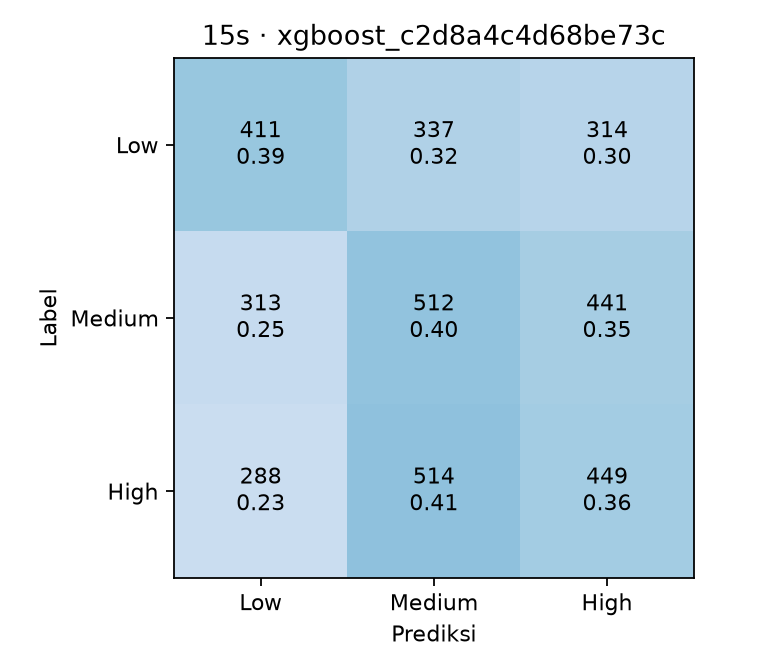

Confusion matrix deskriptif 25s: logistic_499f533391d1cfa0. Ranking outer ini tidak dipakai untuk seleksi model akhir.


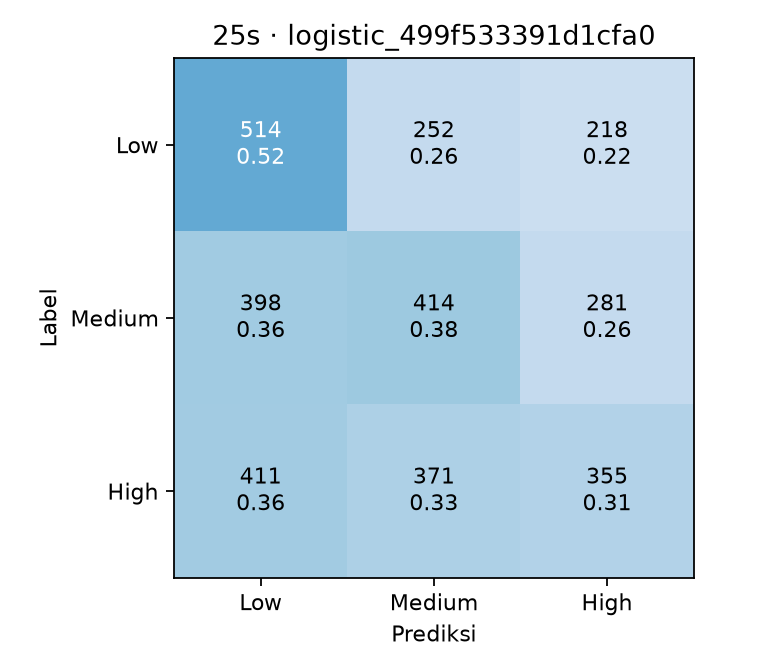

Confusion matrix deskriptif 45s: logistic_499f533391d1cfa0. Ranking outer ini tidak dipakai untuk seleksi model akhir.


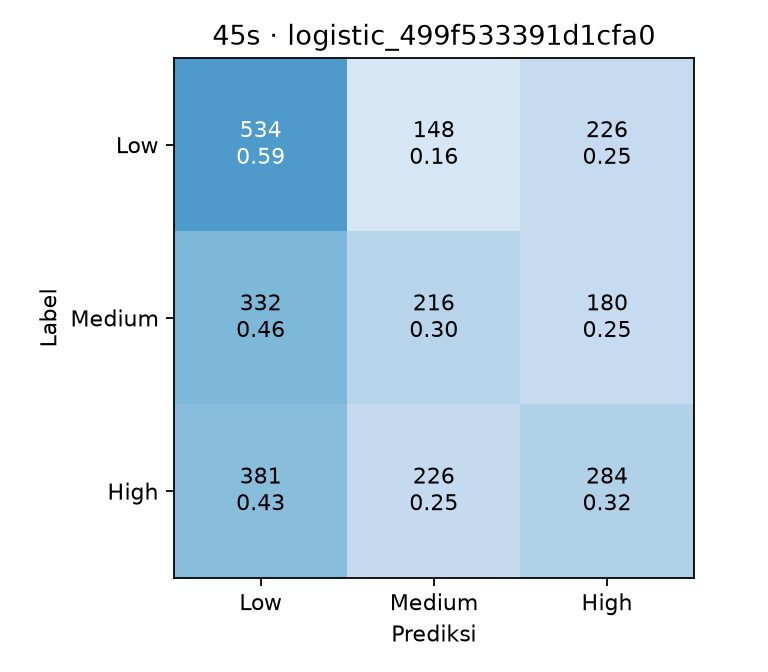

,id,person,status
0,fold_11,Siti,no_test_support


In [7]:
from batch02.reporting import display_notebook_results

display_notebook_results(run_dir)
